In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
project_path = '/content/drive/MyDrive/Online Shopping Clickstream EDA'

data_path = project_path + '/data/raw'

csv_path = data_path + '/e-shop clothing 2008.csv'
txt_path = data_path + '/e-shop clothing 2008 data description.txt'

In [4]:
with open(txt_path, 'r', encoding='cp1252') as file:
    description = file.read()

print(description)

Data description “e-shop clothing 2008”

Variables:

1. YEAR (2008)


2. MONTH -> from April (4) to August (8)


3. DAY -> day number of the month


4. ORDER -> sequence of clicks during one session


5. COUNTRY -> variable indicating the country of origin of the IP address with the 
following categories:

1-Australia
2-Austria
3-Belgium
4-British Virgin Islands
5-Cayman Islands
6-Christmas Island
7-Croatia
8-Cyprus
9-Czech Republic
10-Denmark
11-Estonia
12-unidentified
13-Faroe Islands
14-Finland
15-France
16-Germany
17-Greece
18-Hungary
19-Iceland
20-India
21-Ireland
22-Italy
23-Latvia
24-Lithuania
25-Luxembourg
26-Mexico
27-Netherlands
28-Norway
29-Poland
30-Portugal
31-Romania
32-Russia
33-San Marino
34-Slovakia
35-Slovenia
36-Spain
37-Sweden
38-Switzerland
39-Ukraine
40-United Arab Emirates
41-United Kingdom
42-USA
43-biz (*.biz)
44-com (*.com)
45-int (*.int)
46-net (*.net)
47-org (*.org)


6. SESSION ID -> variable indicating session id (short record)


7. PAGE 1 (MAIN CATEGORY) 

In [5]:
df = pd.read_csv(csv_path, sep=None, engine='python')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (165474, 14)


,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1



# E-Commerce Clickstream & Customer Behavior Analysis

## 1. Introduction

### Objective

The objective of this project is to analyse online shopping clickstream data to understand how users interact with an e-commerce website and identify patterns in browsing behaviour.

### Dataset

The dataset is obtained from the UCI Machine Learning Repository – Clickstream Data for Online Shopping.

### Tools & Libraries

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### 2. Data Understanding


In [6]:
display(df.head())

df.info()

display(df.describe())

display(df.describe(include='object'))

,year,month,day,order,country,session ID,page 1 (main category),page 2 (clothing model),colour,location,model photography,price,price 2,page
0,2008,4,1,1,29,1,1,A13,1,5,1,28,2,1
1,2008,4,1,2,29,1,1,A16,1,6,1,33,2,1
2,2008,4,1,3,29,1,2,B4,10,2,1,52,1,1
3,2008,4,1,4,29,1,2,B17,6,6,2,38,2,1
4,2008,4,1,5,29,1,2,B8,4,3,2,52,1,1


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 165474 entries, 0 to 165473
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   year                     165474 non-null  int64 
 1   month                    165474 non-null  int64 
 2   day                      165474 non-null  int64 
 3   order                    165474 non-null  int64 
 4   country                  165474 non-null  int64 
 5   session ID               165474 non-null  int64 
 6   page 1 (main category)   165474 non-null  int64 
 7   page 2 (clothing model)  165474 non-null  object
 8   colour                   165474 non-null  int64 
 9   location                 165474 non-null  int64 
 10  model photography        165474 non-null  int64 
 11  price                    165474 non-null  int64 
 12  price 2                  165474 non-null  int64 
 13  page                     165474 non-null  int64 
dtypes: int64(13), object

,year,month,day,order,country,session ID,page 1 (main category),colour,location,model photography,price,price 2,page
count,165474.0,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000,165474.000000
mean,2008.0,5.585887,14.524554,9.817476,26.952621,12058.417056,2.400842,6.227655,3.258198,1.260071,43.802507,1.488167,1.710166
std,0.0,1.328160,8.830374,13.478411,7.150691,7008.418903,1.144420,4.235606,1.713206,0.438674,12.548131,0.499861,0.982412
min,2008.0,4.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,18.000000,1.000000,1.000000
25%,2008.0,4.000000,7.000000,2.000000,29.000000,5931.000000,1.000000,3.000000,2.000000,1.000000,33.000000,1.000000,1.000000
50%,2008.0,5.000000,14.000000,6.000000,29.000000,11967.500000,2.000000,4.000000,3.000000,1.000000,43.000000,1.000000,1.000000
75%,2008.0,7.000000,22.000000,12.000000,29.000000,18219.000000,3.000000,9.000000,5.000000,2.000000,52.000000,2.000000,2.000000
max,2008.0,8.000000,31.000000,195.000000,47.000000,24026.000000,4.000000,14.000000,6.000000,2.000000,82.000000,2.000000,5.000000


,page 2 (clothing model)
count,165474
unique,217
top,B4
freq,3579


In [7]:
print("Columns in the dataset:")
print(df.columns.tolist())

print("\nDataset shape:", df.shape)

Columns in the dataset:
['year', 'month', 'day', 'order', 'country', 'session ID', 'page 1 (main category)', 'page 2 (clothing model)', 'colour', 'location', 'model photography', 'price', 'price 2', 'page']

Dataset shape: (165474, 14)


In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())
print("Number of duplicate rows:", df.duplicated().sum())

Missing values in each column:
year                       0
month                      0
day                        0
order                      0
country                    0
session ID                 0
page 1 (main category)     0
page 2 (clothing model)    0
colour                     0
location                   0
model photography          0
price                      0
price 2                    0
page                       0
dtype: int64

Total missing values: 0
Number of duplicate rows: 0


In [9]:
print("Number of unique values in each column:")
print(df.nunique())

Number of unique values in each column:
year                           1
month                          5
day                           31
order                        195
country                       47
session ID                 24026
page 1 (main category)         4
page 2 (clothing model)      217
colour                        14
location                       6
model photography              2
price                         20
price 2                        2
page                           5
dtype: int64


In [10]:
print("Descriptive Statistics:")
display(df.describe().T)

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
year,165474.0,2008.000000,0.000000,2008.0,2008.0,2008.0,2008.0,2008.0
month,165474.0,5.585887,1.328160,4.0,4.0,5.0,7.0,8.0
day,165474.0,14.524554,8.830374,1.0,7.0,14.0,22.0,31.0
order,165474.0,9.817476,13.478411,1.0,2.0,6.0,12.0,195.0
country,165474.0,26.952621,7.150691,1.0,29.0,29.0,29.0,47.0
session ID,165474.0,12058.417056,7008.418903,1.0,5931.0,11967.5,18219.0,24026.0
page 1 (main category),165474.0,2.400842,1.144420,1.0,1.0,2.0,3.0,4.0
colour,165474.0,6.227655,4.235606,1.0,3.0,4.0,9.0,14.0
location,165474.0,3.258198,1.713206,1.0,2.0,3.0,5.0,6.0
model photography,165474.0,1.260071,0.438674,1.0,1.0,1.0,2.0,2.0


In [11]:
print("Minimum and Maximum Values:")

for col in df.select_dtypes(include='number').columns:
    print(f"{col}: Min = {df[col].min()}, Max = {df[col].max()}")

Minimum and Maximum Values:
year: Min = 2008, Max = 2008
month: Min = 4, Max = 8
day: Min = 1, Max = 31
order: Min = 1, Max = 195
country: Min = 1, Max = 47
session ID: Min = 1, Max = 24026
page 1 (main category): Min = 1, Max = 4
colour: Min = 1, Max = 14
location: Min = 1, Max = 6
model photography: Min = 1, Max = 2
price: Min = 18, Max = 82
price 2: Min = 1, Max = 2
page: Min = 1, Max = 5


In [12]:
dates = pd.to_datetime(df[['year', 'month', 'day']], errors='coerce')

print("Invalid date records:", dates.isnull().sum())

Invalid date records: 0


In [13]:
# Checking outliers using the IQR method

for col in ['order', 'price']:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_limit) | (df[col] > upper_limit)]

    print(f"\nColumn: {col}")
    print("Lower Limit:", lower_limit)
    print("Upper Limit:", upper_limit)
    print("Number of Outliers:", len(outliers))


Column: order
Lower Limit: -13.0
Upper Limit: 27.0
Number of Outliers: 11523

Column: price
Lower Limit: 4.5
Upper Limit: 80.5
Number of Outliers: 1923


### Data Cleaning Summary

The dataset was checked for missing values, duplicate records, incorrect data types, invalid date combinations and potential outliers.

- **Missing Values:** No missing values were found.
- **Duplicate Records:** No duplicate rows were found.
- **Data Types:** The data types were found to be appropriate for the dataset.
- **Invalid Values:** The numerical ranges and date combinations were checked. No invalid values were identified.
- **Outliers:** The IQR method flagged 11,523 potential outliers in the `order` column and 1,923 in the `price` column. These records were retained because they may represent genuine user browsing activity and valid product prices.

No records were removed during data cleaning because no confirmed data errors were identified.

In [14]:
print("Product Category Distribution:")
print(df['page 1 (main category)'].value_counts().sort_index())

Product Category Distribution:
page 1 (main category)
1    49742
2    38408
3    38577
4    38747
Name: count, dtype: int64


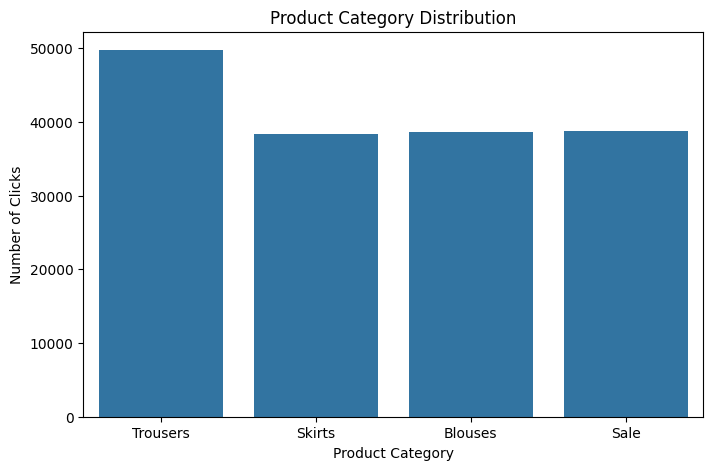

In [15]:
plt.figure(figsize=(8, 5))

category_counts = df['page 1 (main category)'].value_counts().sort_index()

category_names = ['Trousers', 'Skirts', 'Blouses', 'Sale']

sns.barplot(x=category_names, y=category_counts.values)

plt.title('Product Category Distribution')
plt.xlabel('Product Category')
plt.ylabel('Number of Clicks')
plt.show()

### Q1. Which product categories receive the most attention?

Trousers received the highest attention with **49,742 clicks**, followed by Sale (38,747), Blouses (38,577) and Skirts (38,408).

**Insight:** Trousers attract more browsing activity than the other product categories.

In [16]:
print("Page Click Distribution:")
print(df['page'].value_counts().sort_index())

Page Click Distribution:
page
1    93452
2    41037
3    19301
4     8861
5     2823
Name: count, dtype: int64


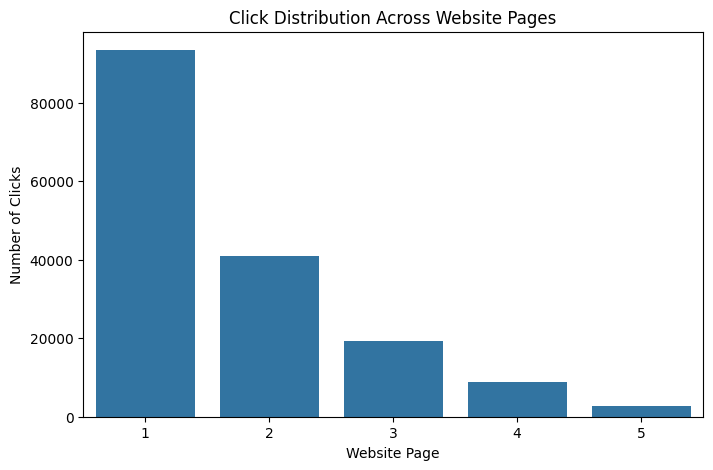

In [17]:
plt.figure(figsize=(8, 5))

page_counts = df['page'].value_counts().sort_index()

sns.barplot(x=page_counts.index, y=page_counts.values)

plt.title('Click Distribution Across Website Pages')
plt.xlabel('Website Page')
plt.ylabel('Number of Clicks')
plt.show()

### Q2. Which pages attract the most clicks?

Page 1 attracts the highest attention with **93,452 clicks**, followed by Page 2 (41,037), while Page 5 receives the fewest clicks (2,823).

**Insight:** User activity decreases considerably as the website page number increases, indicating that most browsing activity occurs on the first few pages.

Click Distribution by Product Price:
price
18      280
20     1433
23     3992
26      844
28    18262
33    18749
38    33883
43    22751
48    17878
50      764
52     9279
55     1199
57    11884
60     1641
62    14383
65      402
67     3811
72     1932
77      184
82     1923
Name: count, dtype: int64


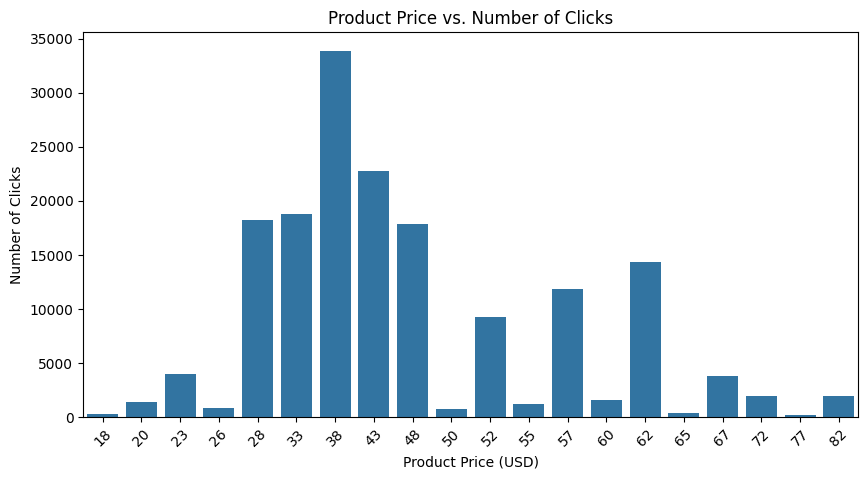

In [18]:
price_counts = df['price'].value_counts().sort_index()

print("Click Distribution by Product Price:")
print(price_counts)

plt.figure(figsize=(10, 5))

sns.barplot(x=price_counts.index, y=price_counts.values)

plt.title('Product Price vs. Number of Clicks')
plt.xlabel('Product Price (USD)')
plt.ylabel('Number of Clicks')
plt.xticks(rotation=45)
plt.show()

### Q3. Does product price affect user behaviour?

Products priced at 38 USD receive the highest attention with 33,883 clicks, while products priced at 77 USD receive the fewest clicks (184).

**Insight:** Browsing activity varies across different price points, but click frequency alone does not prove that price influences user behaviour.

In [19]:
country_names = {
    1: 'Australia', 2: 'Austria', 3: 'Belgium',
    4: 'British Virgin Islands', 5: 'Cayman Islands',
    6: 'Christmas Island', 7: 'Croatia', 8: 'Cyprus',
    9: 'Czech Republic', 10: 'Denmark', 11: 'Estonia',
    12: 'Unidentified', 13: 'Faroe Islands', 14: 'Finland',
    15: 'France', 16: 'Germany', 17: 'Greece',
    18: 'Hungary', 19: 'Iceland', 20: 'India',
    21: 'Ireland', 22: 'Italy', 23: 'Latvia',
    24: 'Lithuania', 25: 'Luxembourg', 26: 'Mexico',
    27: 'Netherlands', 28: 'Norway', 29: 'Poland',
    30: 'Portugal', 31: 'Romania', 32: 'Russia',
    33: 'San Marino', 34: 'Slovakia', 35: 'Slovenia',
    36: 'Spain', 37: 'Sweden', 38: 'Switzerland',
    39: 'Ukraine', 40: 'United Arab Emirates',
    41: 'United Kingdom', 42: 'USA',
    43: '.biz', 44: '.com', 45: '.int',
    46: '.net', 47: '.org'
}

country_counts = df['country'].value_counts().head(10)

top_countries = country_counts.rename(index=country_names)

print("Top 10 Countries by Click Activity:")
print(top_countries)

Top 10 Countries by Click Activity:
country
Poland            133963
Czech Republic     18003
Lithuania           4091
.net                2522
.com                1385
Germany              834
Ireland              811
Slovakia             716
United Kingdom       684
Belgium              256
Name: count, dtype: int64


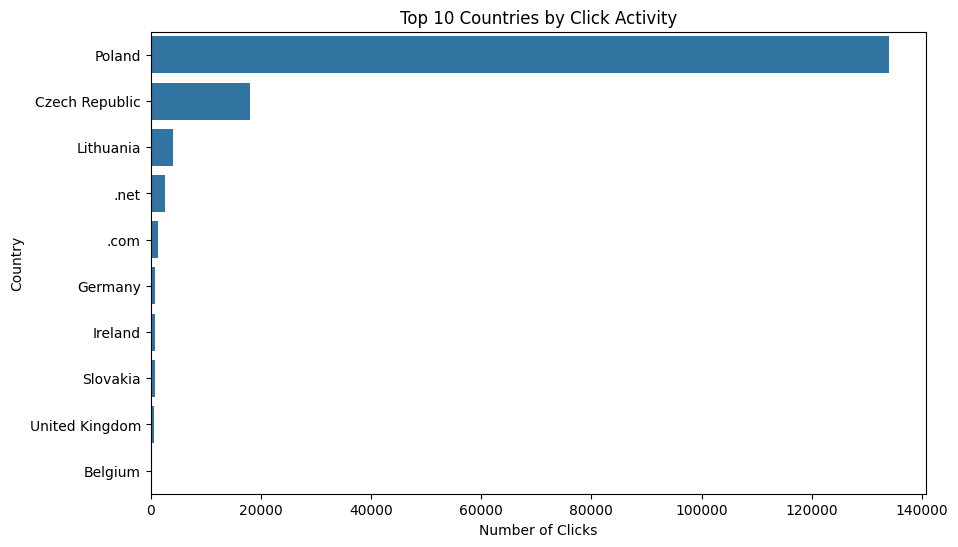

In [20]:
plt.figure(figsize=(10, 6))

sns.barplot(x=top_countries.values, y=top_countries.index)

plt.title('Top 10 Countries by Click Activity')
plt.xlabel('Number of Clicks')
plt.ylabel('Country')
plt.show()

### Q4. Which countries generate the most activity?

Poland records the highest activity with **133,963 clicks**, followed by the Czech Republic (18,003) and Lithuania (4,091). The remaining countries have considerably fewer clicks.

**Insight:** Poland is the major source of browsing activity in this dataset. Note that `.net` and `.com` are domain categories, not countries.

In [21]:
location_names = {
    1: 'Top Left',
    2: 'Top Middle',
    3: 'Top Right',
    4: 'Bottom Left',
    5: 'Bottom Middle',
    6: 'Bottom Right'
}

location_counts = df['location'].value_counts().sort_index()
location_counts.index = location_counts.index.map(location_names)

print("Click Distribution by Page Location:")
print(location_counts)

Click Distribution by Page Location:
location
Top Left         34532
Top Middle       33383
Top Right        21656
Bottom Left      27377
Bottom Middle    27783
Bottom Right     20743
Name: count, dtype: int64


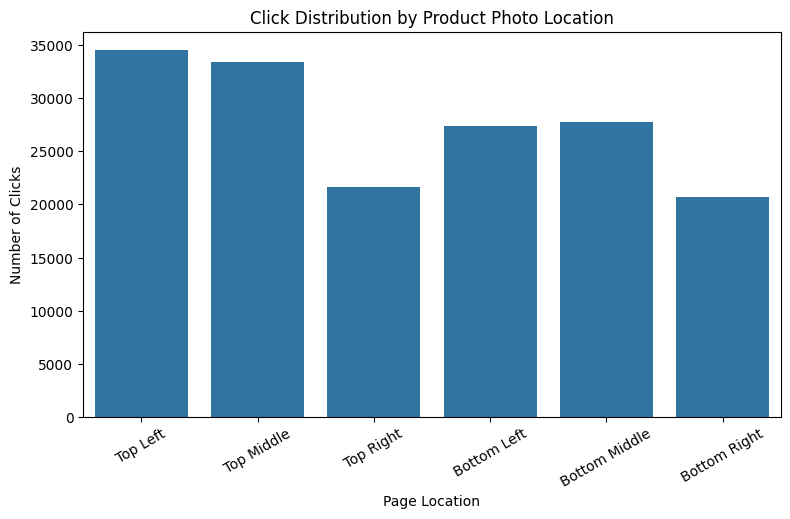

In [22]:
plt.figure(figsize=(9, 5))

sns.barplot(x=location_counts.index, y=location_counts.values)

plt.title('Click Distribution by Product Photo Location')
plt.xlabel('Page Location')
plt.ylabel('Number of Clicks')
plt.xticks(rotation=30)
plt.show()

### Q5. What are the most frequently visited page locations?

The Top Left position receives the highest attention with 34,532 clicks, followed by Top Middle (33,383). Bottom Right receives the fewest clicks, with 20,743.

**Insight:** Product images positioned in the upper section of the webpage generally receive more browsing attention than those in the bottom-right position.

In [23]:
category_names = {
    1: 'Trousers',
    2: 'Skirts',
    3: 'Blouses',
    4: 'Sale'
}

location_names = {
    1: 'Top Left',
    2: 'Top Middle',
    3: 'Top Right',
    4: 'Bottom Left',
    5: 'Bottom Middle',
    6: 'Bottom Right'
}

category_location = pd.crosstab(
    df['page 1 (main category)'],
    df['location']
)

category_location.index = category_location.index.map(category_names)
category_location.columns = category_location.columns.map(location_names)

print("Click Distribution Across Product Categories and Locations:")
display(category_location)

Click Distribution Across Product Categories and Locations:


location,Top Left,Top Middle,Top Right,Bottom Left,Bottom Middle,Bottom Right
page 1 (main category),,,,,,
Trousers,11192,9760,6635,8998,7899,5258
Skirts,6406,8482,4808,7471,7744,3497
Blouses,7713,7814,5122,5354,6273,6301
Sale,9221,7327,5091,5554,5867,5687


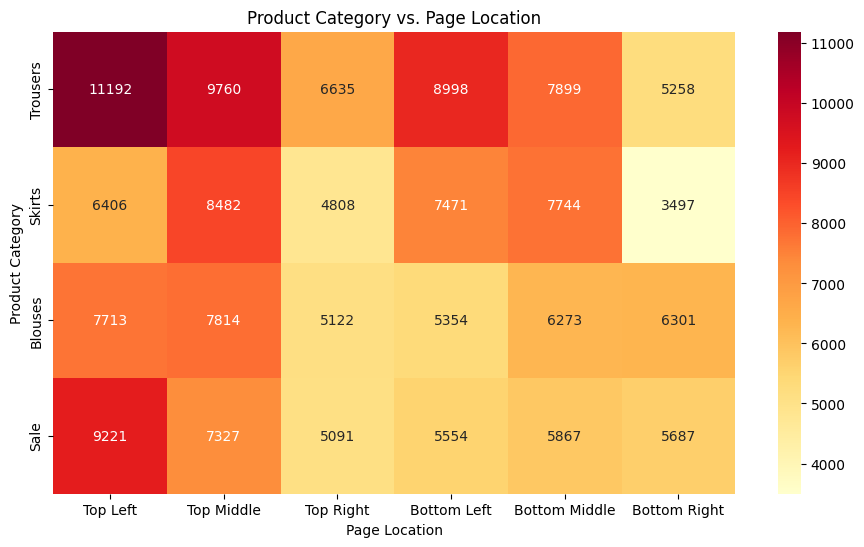

In [24]:
plt.figure(figsize=(11, 6))

sns.heatmap(category_location, annot=True, fmt='d', cmap='YlOrRd')

plt.title('Product Category vs. Page Location')
plt.xlabel('Page Location')
plt.ylabel('Product Category')
plt.show()

### Q6. Are there differences in behaviour across product categories?

Trousers receive the highest clicks at the Top Left position (11,192), while Skirts receive the highest clicks at Top Middle (8,482). Blouses show relatively high activity at Bottom Right (6,301), unlike the other categories.

**Insight:** User attention varies across product categories and photo positions, suggesting that product placement may influence browsing activity.

In [25]:
session_activity = df.groupby('session ID').agg(
    total_clicks=('order', 'count'),
    unique_categories=('page 1 (main category)', 'nunique'),
    unique_products=('page 2 (clothing model)', 'nunique'),
    pages_visited=('page', 'nunique')
)

print("Session Browsing Activity:")
display(session_activity.describe())

Session Browsing Activity:


,total_clicks,unique_categories,unique_products,pages_visited
count,24026.000000,24026.000000,24026.000000,24026.000000
mean,6.887289,1.851661,6.174353,1.946183
std,8.995161,0.956479,7.525282,1.125865
min,1.000000,1.000000,1.000000,1.000000
25%,2.000000,1.000000,2.000000,1.000000
50%,4.000000,2.000000,4.000000,2.000000
75%,8.000000,3.000000,8.000000,3.000000
max,195.000000,4.000000,168.000000,5.000000


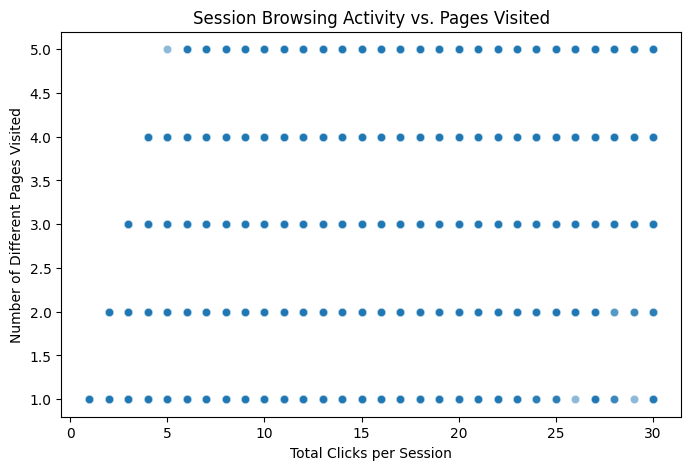

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=session_activity[session_activity['total_clicks'] <= 30],
    x='total_clicks',
    y='pages_visited',
    alpha=0.5
)

plt.title('Session Browsing Activity vs. Pages Visited')
plt.xlabel('Total Clicks per Session')
plt.ylabel('Number of Different Pages Visited')
plt.show()

### Q7. What patterns can be identified between browsing activity and purchasing behaviour?

Across 24,026 sessions, users generated an average of 6.89 clicks and visited approximately 2 different website pages per session. The maximum browsing activity reached 195 clicks in a single session.

**Insight:** Browsing activity varies considerably across sessions. However, the dataset does not contain confirmed purchase records, so a direct relationship between browsing activity and actual purchasing behaviour cannot be established.

In [27]:
session_corr = session_activity[
    ['total_clicks', 'unique_categories',
     'unique_products', 'pages_visited']
].corr()

print("Correlation Between Browsing Variables:")
display(session_corr)

Correlation Between Browsing Variables:


,total_clicks,unique_categories,unique_products,pages_visited
total_clicks,1.000000,0.565768,0.971397,0.603628
unique_categories,0.565768,1.000000,0.600928,0.587986
unique_products,0.971397,0.600928,1.000000,0.637883
pages_visited,0.603628,0.587986,0.637883,1.000000


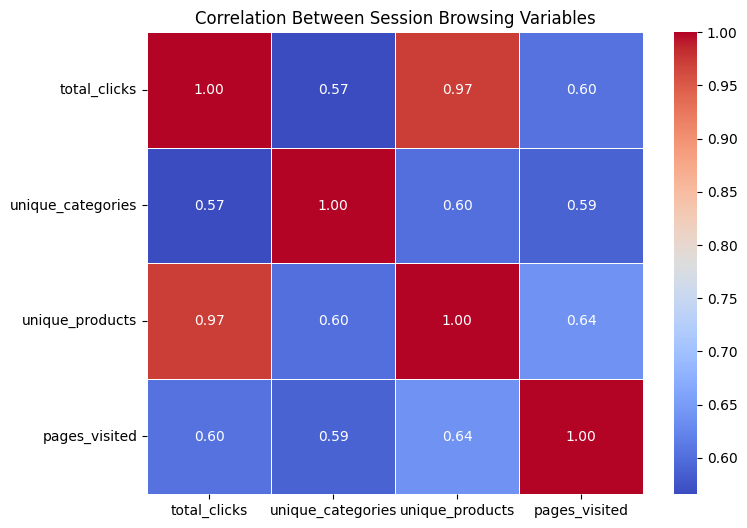

In [28]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    session_corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Session Browsing Variables')
plt.show()

### Q8. Which variables appear to be associated with customer conversion?

Total clicks and unique products show a very strong positive correlation of **0.97**. Pages visited also show moderate positive correlations with total clicks (0.60) and unique products (0.64).

**Insight:** Higher browsing activity is associated with exploring more products and pages. However, actual customer conversion cannot be determined because the dataset does not contain purchase records.

In [29]:
#IQR for total clicks per session
Q1 = session_activity['total_clicks'].quantile(0.25)
Q3 = session_activity['total_clicks'].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

#Identify unusual sessions
session_outliers = session_activity[
    (session_activity['total_clicks'] < lower_limit) |
    (session_activity['total_clicks'] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Number of Unusual Sessions:", len(session_outliers))

print("\nTop 10 Sessions by Browsing Activity:")
display(session_activity.nlargest(10, 'total_clicks'))

Lower Limit: -7.0
Upper Limit: 17.0
Number of Unusual Sessions: 1962

Top 10 Sessions by Browsing Activity:


,total_clicks,unique_categories,unique_products,pages_visited
session ID,,,,
22433,195,4,168,5
13846,192,3,134,4
22902,185,4,157,5
8201,161,4,157,5
19623,142,3,133,4
14191,128,3,119,5
8790,121,3,61,5
19464,120,3,99,5
6592,112,1,60,5


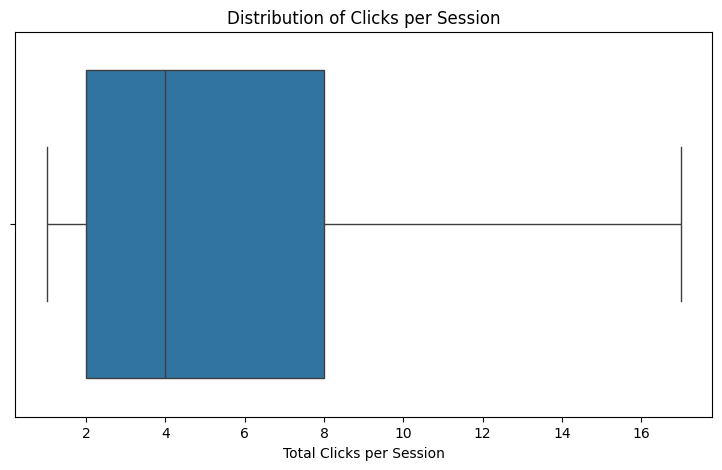

In [31]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    x=session_activity['total_clicks'],
    showfliers=False
)

plt.title('Distribution of Clicks per Session')
plt.xlabel('Total Clicks per Session')
plt.show()

### Q9. Are there unusual user behaviours or outliers?

The IQR method identified **1,962 unusual sessions** with more than 17 clicks. The most active session recorded 195 clicks and explored 168 unique products across all four product categories.

**Insight:** A small group of sessions shows exceptionally high browsing activity. These may represent highly engaged users or unusual browsing patterns and should be investigated further.

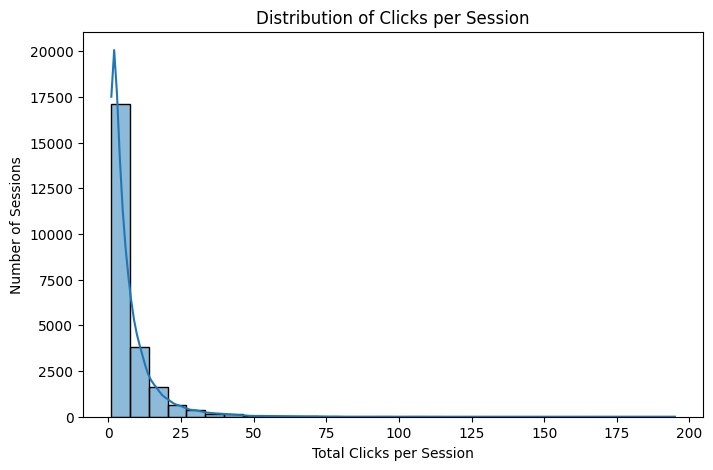

In [33]:
#Additional Visualization 1: Session Activity Distribution
plt.figure(figsize=(8, 5))

sns.histplot(
    data=session_activity,
    x='total_clicks',
    bins=30,
    kde=True
)

plt.title('Distribution of Clicks per Session')
plt.xlabel('Total Clicks per Session')
plt.ylabel('Number of Sessions')
plt.show()

### Additional Visualization 1: Session Activity Distribution

The histogram shows that most users make a relatively small number of clicks per session. The distribution is strongly right-skewed, with a small number of sessions recording significantly higher clicks, reaching up to 195.

**Insight:** Most browsing sessions involve limited activity, while a smaller group of sessions shows much higher engagement.

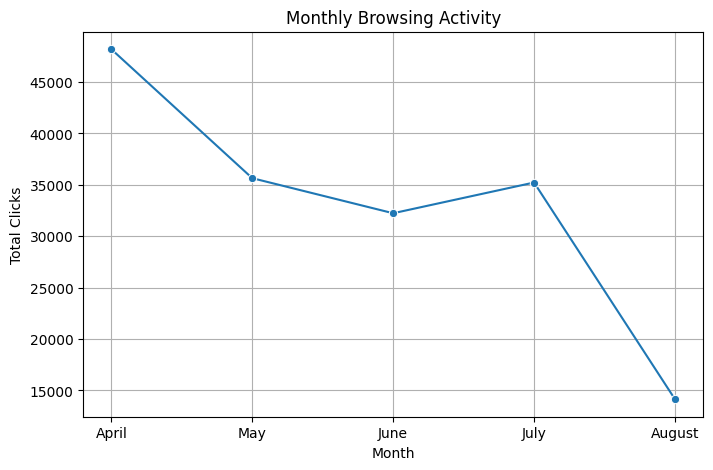

In [34]:
#Additional Visualization 2: Monthly Browsing Activity
monthly_activity = df.groupby('month').size()

plt.figure(figsize=(8, 5))

sns.lineplot(
    x=monthly_activity.index,
    y=monthly_activity.values,
    marker='o'
)

plt.title('Monthly Browsing Activity')
plt.xlabel('Month')
plt.ylabel('Total Clicks')
plt.xticks([4, 5, 6, 7, 8], ['April', 'May', 'June', 'July', 'August'])
plt.grid(True)
plt.show()

### Additional Visualization 2: Monthly Browsing Activity

April recorded the highest browsing activity with approximately 48,200 clicks. Activity declined during May and June, increased slightly in July, and dropped considerably in August to approximately 14,200 clicks.

**Insight:** Browsing activity varied across the five months, with an overall declining trend. Further investigation would be needed to determine the reason for these changes.

## Insights and Recommendations

### 1. Business Recommendations

- **Optimize product placement:** Give greater visibility to popular product categories, especially Trousers, and consider testing product image positions to improve user engagement.
- **Improve website navigation:** Since Page 1 receives the highest number of clicks, make important products and categories easily accessible from the initial pages.
- **Use browsing patterns for product planning:** Products priced at 38 USD received the highest click activity. Analyse product-level interest further before making pricing or promotional decisions.
- **Focus on major customer regions:** Poland generated the highest browsing activity, followed by the Czech Republic and Lithuania. Consider prioritizing these regions when planning website improvements and marketing strategies.
- **Improve session engagement:** Most sessions involve relatively few clicks. Explore ways to encourage users to discover more products and navigate through additional pages.
- **Monitor browsing trends:** Monthly activity varied considerably, so track website engagement over time to identify changes and plan appropriate improvements.

### 2. Limitations of the Analysis

- The dataset contains clickstream records from 2008, so the observed patterns may not represent current online shopping behaviour.
- The dataset records browsing activity but does not contain confirmed purchase records or an explicit conversion variable.
- Click frequency does not necessarily indicate customer interest, purchase intention or actual sales.
- The dataset contains coded categorical variables, such as country, product category and colour, which require reference mappings for interpretation.
- Monthly browsing activity is based on total clicks, and differences in observation periods or sample sizes may affect comparisons.
- The analysis identifies associations and browsing patterns, not causal relationships.

### 3. Conclusion

The analysis identified meaningful patterns in online shopping activity, including differences in product category attention, page visits, geographical activity, product placement and session engagement. Trousers and Page 1 received the highest browsing attention, while Poland contributed the largest share of recorded activity. Session analysis also revealed considerable variation in browsing behaviour, with a small number of highly active sessions. These findings can help guide website layout improvements and user engagement strategies, although actual purchasing behaviour and customer conversion cannot be evaluated using this dataset.